# Site Selection
Builds `regions.parquet` (used by main.py to download gee data) and `labels.parquet` (used by corals_dataset_builder.py as ground truth) from Reef Check Belt.csv.
A subset of the data (N_SITES = 12) is used for local code development purposes. The full dataset (N_SITES = "all") in Indo-Pacific region is used to create the final `labels.parquet` file.
Uses % of Population Bleaching, S1-S4 is averaged 

Run this notebook in local venv, bc required belt.csv not included in git, therefore not in docker

In [1]:
import pandas as pd



N_SITES = "all"
REGION = "Indo-Pacific" 
SEVERE_BLEACHING_THRESHOLD = 0
MIN_LABEL_QUARTERS = 0 #test if better results if very dominant 1 labeled quarter sites are excluded
START_QUARTER = "2000-01-01"#change both dates!!!!!!!!!!!!!!!!!!!!
END_QUARTER = "2024-04-01"
SEGMENT_COLUMNS = ["s1 (0-20m)", "s2 (25-45m)", "s3 (50-70m)", "s4 (75-95m)"]

belt = pd.read_csv(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\Belt.csv")


In [2]:
df_belt = pd.DataFrame(belt)
df_belt.head()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df_belt.shape)
df_belt.head()

(678948, 30)


,site_id,survey_id,static_descriptors_reef_id (archived field),reef_name,coordinates_in_decimal_degree_format,longitude_degrees,longitude_minutes,longitude_seconds,longitude_cardinal_direction,latitude_degrees,latitude_minutes,latitude_seconds,latitude_cardinal_direction,country,state_province_island,city_town,region,year,date,depth (m),organism_code,type,s1 (0-20m),s2 (25-45m),s3 (50-70m),s4 (75-95m),fish_recorded_by,inverts_recorded_by,errors,what_errors
0,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Butterflyfish,Fish,6,10,12,0,NaN,NaN,False,NaN
1,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Haemulidae,Fish,0,1,0,0,NaN,NaN,False,NaN
2,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Snapper,Fish,2,0,2,2,NaN,NaN,False,NaN
3,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Barramundi Cod,Fish,0,0,0,0,NaN,NaN,False,NaN
4,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,20-April-16,3.0,Humphead Wrasse,Fish,0,0,0,0,NaN,NaN,False,NaN


## Bleaching Sum and Formatting

In [3]:
belt[SEGMENT_COLUMNS] = belt[SEGMENT_COLUMNS].apply(pd.to_numeric, errors="coerce") # blanks in s1-s4 ->NaN
pop = belt[belt["organism_code"] == "Bleaching (% Of Population)"].copy() # extract bleaching
pop["bleaching_percent"] = pop[SEGMENT_COLUMNS].mean(axis=1, skipna=True) # average s1-s4, ignore blanks

pop["date"] = pd.to_datetime(pop["date"], errors="coerce")
pop["quarter"] = pop["date"].dt.to_period("Q").dt.start_time # converts survey dates to quarter

coords = pop["coordinates_in_decimal_degree_format"].astype(str).str.split(",", expand=True) # split longitude, latitude
pop["lat"] = pd.to_numeric(coords[0].str.strip(), errors="coerce")
pop["lon"] = pd.to_numeric(coords[1].str.strip(), errors="coerce")

print(pop.shape)
pop.head()

C:\Users\ohlle\AppData\Local\Temp\ipykernel_796\3923164910.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pop["date"] = pd.to_datetime(pop["date"], errors="coerce")


(16949, 34)


,site_id,survey_id,static_descriptors_reef_id (archived field),reef_name,coordinates_in_decimal_degree_format,longitude_degrees,longitude_minutes,longitude_seconds,longitude_cardinal_direction,latitude_degrees,latitude_minutes,latitude_seconds,latitude_cardinal_direction,country,state_province_island,city_town,region,year,date,depth (m),organism_code,type,s1 (0-20m),s2 (25-45m),s3 (50-70m),s4 (75-95m),fish_recorded_by,inverts_recorded_by,errors,what_errors,bleaching_percent,quarter,lat,lon
33,6a8719bb-91fe-46c1-9635-37fb1f022ea9,000887f9-b8c4-4c43-bc63-700c0e8b385b,119.18.33.5E.11.0.57.5N,Masigasig/Esteban Reef,"11.015972, 119.309306",119,18,33.5,E,11,0,57.5,N,Philippines,Palawan,Taytay,Indo-Pacific,2016,2016-04-20,3.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,NaN,NaN,False,NaN,0.00,2016-04-01,11.015972,119.309306
73,165deb2d-692c-49c9-889d-7ce5c6156657,00103835-7d8a-4099-a58b-bac77e8e81bc,129.57.21.3E.4.32.59.2S,Banda Besar 4.55,"-4.549778, 129.955917",129,57,21.3,E,4,32,59.2,S,Indonesia,Maluku Tengah,Banda Naira,Indo-Pacific,2018,2018-12-08,10.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,"Carolina Menze, Emil Sjahman","Carolina Menze, Emil Sjahman",False,NaN,0.00,2018-10-01,-4.549778,129.955917
113,35a4fe9c-76e0-4961-a0eb-0953acf2dc7e,0016ef4b-d18c-4ace-a821-ec622688a708,124.40.11.3E.10.30.57.9N,Mahaba Marine Sanctuary,"10.516083, 124.669806",124,40,11.3,E,10,30,57.9,N,Philippines,Leyte,Inopacan Municipality,Indo-Pacific,2008,2008-07-24,12.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,NaN,NaN,False,NaN,0.00,2008-07-01,10.516083,124.669806
153,ba897ac0-d2e4-453c-946c-934f8b9ba838,001a09e0-e52f-4adf-bb2d-e66e2bacb3b5,151.47.2.3W.16.29.57.9S,Tapu (external slope),"-16.499417, -151.783972",151,47,2.3,W,16,29,57.9,S,French Polynesia,NaN,Bora Bora,Indo-Pacific,2014,2014-10-19,7.0,Bleaching (% Of Population),Impact,0.0,0.0,0.0,0.0,NaN,NaN,False,NaN,0.00,2014-10-01,-16.499417,-151.783972
193,9067f611-93bd-4e0b-97cc-94d9b4ec4266,001adbf1-e2eb-4ef7-b600-bd8a923e0020,103.57.36.1E.2.32.54.8N,Pulau Mensirip Transect 2,"2.548556, 103.960028",103,57,36.1,E,2,32,54.8,N,Malaysia,Johor,Mersing,Indo-Pacific,2022,2022-08-23,5.2,Bleaching (% Of Population),Impact,0.0,0.0,0.0,1.0,"Izzat bin A'rizu, SIVA PRAKASH A/L ARIKRISHNAN",SIVA PRAKASH A/L ARIKRISHNAN,NaN,NaN,0.25,2022-07-01,2.548556,103.960028


In [4]:
pop = pop.dropna(subset=["site_id", "quarter", "bleaching_percent", "lat", "lon"]) #remove rows with missing values
pop.shape

(14512, 34)

In [5]:
time_index = pd.date_range(START_QUARTER, END_QUARTER, freq="QS") # dates expected by existing scripts
pop = pop[pop["quarter"].isin(time_index)].copy() # keep only data in time range
pop.shape

(13754, 34)

In [6]:
site_id_counts_per_region = (
    pop.groupby("region")["site_id"]
    .nunique()
    .sort_values(ascending=False)
    .to_frame()
    .T
)

site_id_counts_per_region.index = ["n_site_ids"]
site_id_counts_per_region

region,Indo-Pacific,Atlantic,Red Sea,Arabian Gulf,Hawaii,East Pacific
n_site_ids,3145,985,184,74,51,7


In [7]:
# check reef depth variation
shallow_reefs = (
    pop.loc[
        pop["depth (m)"] < 15,
        ["site_id", "depth (m)", "date", "reef_name", "bleaching_percent", "lat", "lon"],
    ]
    .sort_values("site_id")
)

site_observation_counts = shallow_reefs.groupby("site_id").size()
sites_with_enough_observations = site_observation_counts[site_observation_counts >= 4].index

shallow_reefs = shallow_reefs[shallow_reefs["site_id"].isin(sites_with_enough_observations)].copy()
shallow_reefs = shallow_reefs.sort_values(["site_id", "date"])
shallow_reefs.head(20)

,site_id,depth (m),date,reef_name,bleaching_percent,lat,lon
166344,00551c69-1dd7-4742-8d2f-091ab1848e45,9.0,2013-01-17,Twin Peaks,0.00,10.116667,99.844444
429708,00551c69-1dd7-4742-8d2f-091ab1848e45,4.5,2013-01-17,Twin Peaks,0.00,10.116667,99.844444
134382,00551c69-1dd7-4742-8d2f-091ab1848e45,9.0,2013-05-10,Twin Peaks,0.00,10.116667,99.844444
305806,00551c69-1dd7-4742-8d2f-091ab1848e45,4.5,2013-05-10,Twin Peaks,5.00,10.116667,99.844444
543941,00551c69-1dd7-4742-8d2f-091ab1848e45,10.0,2014-05-27,Twin Peaks,57.50,10.116667,99.844444
582838,00551c69-1dd7-4742-8d2f-091ab1848e45,5.0,2014-05-27,Twin Peaks,100.00,10.116667,99.844444
587292,00551c69-1dd7-4742-8d2f-091ab1848e45,10.0,2014-07-27,Twin Peaks,12.50,10.116667,99.844444
127779,00551c69-1dd7-4742-8d2f-091ab1848e45,5.0,2014-07-27,Twin Peaks,5.25,10.116667,99.844444
473528,00551c69-1dd7-4742-8d2f-091ab1848e45,5.0,2015-01-29,Twin Peaks,0.00,10.116667,99.844444
11759,00551c69-1dd7-4742-8d2f-091ab1848e45,8.0,2015-01-29,Twin Peaks,0.00,10.116667,99.844444


## Sort severe bleaching sites based on label coverage

For the 12 site subset the dataset was previously sorted, to have sites with severe bleaching included

In [8]:
labels_long = pop.groupby(["site_id", "quarter"], as_index=False).agg(bleaching_percent=("bleaching_percent", "mean")) # average if site has more than one survey in the same quarter

site_info = (
    pop.sort_values("date")
    .groupby("site_id", as_index=False)
    .agg(
        reef_name=("reef_name", "first"),
        region=("region", "first"),
        country=("country", "first"),
        lat=("lat", "first"),
        lon=("lon", "first"),
        depth=("depth (m)", "first"),
    )
) # collect one coordinate and name per site

site_stats = (
    labels_long.groupby("site_id", as_index=False)
    .agg(
        n_label_quarters=("quarter", "nunique"),
        max_pop_bleaching=("bleaching_percent", "max"),
        min_pop_bleaching=("bleaching_percent", "min"),
    )
)


candidates = site_info.merge(site_stats, on="site_id", how="inner")
candidates = candidates[
    (candidates["max_pop_bleaching"] >= SEVERE_BLEACHING_THRESHOLD)
    & (candidates["n_label_quarters"] >= MIN_LABEL_QUARTERS)
].copy() 
if REGION != "all":
    candidates = candidates[candidates["region"] == REGION].copy()

candidates = candidates.sort_values(["n_label_quarters", "max_pop_bleaching"], ascending=[False, False]).copy()

candidates.head(12)


,site_id,reef_name,region,country,lat,lon,depth,n_label_quarters,max_pop_bleaching,min_pop_bleaching
2471,8f2a090d-9f8e-49b5-a749-b6e64f7f4902,Sofitel Motu,Indo-Pacific,French Polynesia,-16.535278,-151.728444,1.8,38,25.00,0.0
1318,4dcd2e1d-8e6c-43a7-ab88-828b42f96032,Aquarium,Indo-Pacific,French Polynesia,-16.542389,-151.727028,1.5,38,15.00,0.0
909,34c918c4-48dc-4a17-b06a-e40f8d77452f,Povai,Indo-Pacific,French Polynesia,-16.542694,-151.740778,1.5,37,100.00,0.0
2689,9d85f2d2-d654-4915-a56e-ca3ed1fd0a78,Mohio,Indo-Pacific,French Polynesia,-16.539667,-151.788722,0.8,37,21.25,0.0
2604,98ddf3c1-6689-4e92-96b5-ff99497506ba,Pinacle Marara,Indo-Pacific,French Polynesia,-16.534778,-151.729861,3.0,37,20.00,0.0
3589,d0bdbae0-3ea3-4675-ab5a-c2f6fff2f193,Matira,Indo-Pacific,French Polynesia,-16.552583,-151.732556,0.8,37,20.00,0.0
726,29917b4f-ee50-4d06-ba50-3729ba030462,Jardin de Corail (Coral Garden),Indo-Pacific,French Polynesia,-16.549056,-151.703778,1.0,32,50.00,0.0
3213,ba897ac0-d2e4-453c-946c-934f8b9ba838,Tapu (external slope),Indo-Pacific,French Polynesia,-16.499417,-151.783972,7.0,32,27.50,0.0
4096,ec034f46-ec6d-42ce-b662-b4f874c59f45,Revatua (fringing reef),Indo-Pacific,French Polynesia,-16.479556,-151.720389,1.0,31,39.50,0.0
3548,ce1330dc-75ac-4750-a7c5-2c593f8a4c83,Turiroa,Indo-Pacific,French Polynesia,-16.551472,-151.778389,1.0,31,20.00,0.0


## regions.parquet (used by main.py to download gee data)

In [9]:
# if for training purposes N_SITES is limited, the sorted candidates will be randomly sampled
SPATIAL_SITE_SELECTION_SEED = 42

if N_SITES == "all":
    selected = candidates.sort_values("site_id").copy()
else:
    selected = (
        candidates
        .sort_values("site_id")
        .sample(n=N_SITES, random_state=SPATIAL_SITE_SELECTION_SEED)
        .sort_values("site_id")
        .copy()
    )
   

In [ ]:
###########only temporary for testcornfiles creation##############
#selected = (
#    candidates
#    .head(N_SITES)
#    .sort_values("site_id")
#    .copy()
#)

In [10]:
 
selected_site_ids = selected["site_id"].tolist()

regions = selected[["site_id", "lat", "lon"]]
regions = regions.rename(columns={"site_id": "Site_ID"}) # bc main.py expects
regions.to_parquet(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\regions.parquet", index=False)
regions.head(12)

,Site_ID,lat,lon
1,001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,-12.893750,45.212417
2,002531e9-3466-495d-b219-46912814a50a,10.785889,124.030750
4,00460110-a3fa-4b2c-9ed2-e071e09787b5,4.152306,118.257528
5,00551c69-1dd7-4742-8d2f-091ab1848e45,10.116667,99.844444
6,0069dce1-2fc9-46c7-9bce-10d8460bada7,-26.677194,153.120028
8,0098fca8-d6c6-4859-ba06-74d5207a44ca,10.121028,99.834861
9,009b5024-f412-4606-b016-497c0eb48ae2,-8.340278,116.028611
10,009eb115-e7fe-4675-8bcf-f1803152d35b,5.777056,103.041750
13,00af1f73-5481-46c8-aae1-5f6181217cd6,-3.881667,122.820972
14,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,22.829722,121.188889


In [11]:
regions.shape

(3145, 3)

In [12]:
selected_labels_long = labels_long[labels_long["site_id"].isin(selected_site_ids)].copy()
selected_labels_long["sid"] = "SID_" + selected_labels_long["site_id"].astype(str) # SID_x like in exisiting scripts
labels = selected_labels_long.pivot(index="sid", columns="quarter", values="bleaching_percent").reindex(columns=time_index)
labels = labels.reindex(index=["SID_" + str(site_id) for site_id in selected_site_ids]) #order
labels.to_parquet(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\labels.parquet")
labels.head(12) # NaN's for quarters without survey data->ignored in train.py

,2000-01-01,2000-04-01,2000-07-01,2000-10-01,2001-01-01,2001-04-01,2001-07-01,2001-10-01,2002-01-01,2002-04-01,2002-07-01,2002-10-01,2003-01-01,2003-04-01,2003-07-01,2003-10-01,2004-01-01,2004-04-01,2004-07-01,2004-10-01,2005-01-01,2005-04-01,2005-07-01,2005-10-01,2006-01-01,2006-04-01,2006-07-01,2006-10-01,2007-01-01,2007-04-01,2007-07-01,2007-10-01,2008-01-01,2008-04-01,2008-07-01,2008-10-01,2009-01-01,2009-04-01,2009-07-01,2009-10-01,2010-01-01,2010-04-01,2010-07-01,2010-10-01,2011-01-01,2011-04-01,2011-07-01,2011-10-01,2012-01-01,2012-04-01,2012-07-01,2012-10-01,2013-01-01,2013-04-01,2013-07-01,2013-10-01,2014-01-01,2014-04-01,2014-07-01,2014-10-01,2015-01-01,2015-04-01,2015-07-01,2015-10-01,2016-01-01,2016-04-01,2016-07-01,2016-10-01,2017-01-01,2017-04-01,2017-07-01,2017-10-01,2018-01-01,2018-04-01,2018-07-01,2018-10-01,2019-01-01,2019-04-01,2019-07-01,2019-10-01,2020-01-01,2020-04-01,2020-07-01,2020-10-01,2021-01-01,2021-04-01,2021-07-01,2021-10-01,2022-01-01,2022-04-01,2022-07-01,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01
sid,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
SID_001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_002531e9-3466-495d-b219-46912814a50a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_00460110-a3fa-4b2c-9ed2-e071e09787b5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_00551c69-1dd7-4742-8d2f-091ab1848e45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,2.5,NaN,NaN,NaN,78.75,8.875,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_0069dce1-2fc9-46c7-9bce-10d8460bada7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_0098fca8-d6c6-4859-ba06-74d5207a44ca,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.375,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,1.25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_009b5024-f412-4606-b016-497c0eb48ae2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,

### Convert from percentages to ordinal classes

This section was added to change the project to ordinal classification

- `0`: none, `[0, 1)` percent
- `1`: low, `[1, 10)` percent
- `2`: moderate, `[10, 50]` percent
- `3`: severe, `(50, 100]` percent

In [13]:
def bleaching_percent_to_class(value):
    # Preserve missing quarters.
    if pd.isna(value):
        return float("nan")
    if value < 1:
        return 0.0
    if value < 10:
        return 1.0
    if value <= 50:
        return 2.0
    return 3.0

labels = labels.map(bleaching_percent_to_class).astype("float32")

labels.to_parquet(
    r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\labels.parquet"
)
print("number of quarters per class:")
print(labels.stack().value_counts().sort_index()) #number of quarters per class

labels.head()

number of quarters per class:
0.0    6605
1.0    1682
2.0     493
3.0      64
Name: count, dtype: int64


,2000-01-01,2000-04-01,2000-07-01,2000-10-01,2001-01-01,2001-04-01,2001-07-01,2001-10-01,2002-01-01,2002-04-01,2002-07-01,2002-10-01,2003-01-01,2003-04-01,2003-07-01,2003-10-01,2004-01-01,2004-04-01,2004-07-01,2004-10-01,2005-01-01,2005-04-01,2005-07-01,2005-10-01,2006-01-01,2006-04-01,2006-07-01,2006-10-01,2007-01-01,2007-04-01,2007-07-01,2007-10-01,2008-01-01,2008-04-01,2008-07-01,2008-10-01,2009-01-01,2009-04-01,2009-07-01,2009-10-01,2010-01-01,2010-04-01,2010-07-01,2010-10-01,2011-01-01,2011-04-01,2011-07-01,2011-10-01,2012-01-01,2012-04-01,2012-07-01,2012-10-01,2013-01-01,2013-04-01,2013-07-01,2013-10-01,2014-01-01,2014-04-01,2014-07-01,2014-10-01,2015-01-01,2015-04-01,2015-07-01,2015-10-01,2016-01-01,2016-04-01,2016-07-01,2016-10-01,2017-01-01,2017-04-01,2017-07-01,2017-10-01,2018-01-01,2018-04-01,2018-07-01,2018-10-01,2019-01-01,2019-04-01,2019-07-01,2019-10-01,2020-01-01,2020-04-01,2020-07-01,2020-10-01,2021-01-01,2021-04-01,2021-07-01,2021-10-01,2022-01-01,2022-04-01,2022-07-01,2022-10-01,2023-01-01,2023-04-01,2023-07-01,2023-10-01,2024-01-01,2024-04-01
sid,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
SID_001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_002531e9-3466-495d-b219-46912814a50a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_00460110-a3fa-4b2c-9ed2-e071e09787b5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_00551c69-1dd7-4742-8d2f-091ab1848e45,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,NaN,NaN,NaN,3.0,1.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SID_0069dce1-2fc9-46c7-9bce-10d8460bada7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
labels.shape # format: (sites, quarters)

(3145, 98)

In [15]:
labels.index.is_unique

True

In [16]:
regions["Site_ID"].is_unique

True

# Site-level Spatial Split 
Builds `splits.parquet`: sites are grouped into spatial blocks (nearby reefs stay together) and whole blocks are assigned to train/val/test with a fixed random seed. Sets are balanced on the number of quarters and the severity of bleaching.

In [17]:
spatial_selected = selected.copy()
spatial_selected_site_ids = selected_site_ids

In [18]:
# count number of labeled quarters and number of severe bleaching (>10%) quarters per site
import numpy as np

SPLIT_RANDOM_SEED = 42       
SPATIAL_BLOCK_DEG = 1        # degree size of one spatial block 
SEVERE_QUARTER_THRESHOLD = 10  # quarter is severe if > threshold
SPLIT_TARGET_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15} 


split_labels_long = labels_long[labels_long["site_id"].isin(spatial_selected_site_ids)].copy()
split_labels_long["is_severe_quarter"] = split_labels_long["bleaching_percent"] >= SEVERE_QUARTER_THRESHOLD

site_severity = split_labels_long.groupby("site_id").agg(
    n_label_quarters=("quarter", "nunique"),
    n_severe_bleaching=("is_severe_quarter", "sum"),
)

split_sites = spatial_selected[["site_id", "lat", "lon"]].merge(site_severity, on="site_id", how="left")
split_sites.head(10)

,site_id,lat,lon,n_label_quarters,n_severe_bleaching
0,001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,-12.893750,45.212417,2,0
1,002531e9-3466-495d-b219-46912814a50a,10.785889,124.030750,1,0
2,00460110-a3fa-4b2c-9ed2-e071e09787b5,4.152306,118.257528,1,0
3,00551c69-1dd7-4742-8d2f-091ab1848e45,10.116667,99.844444,5,1
4,0069dce1-2fc9-46c7-9bce-10d8460bada7,-26.677194,153.120028,1,0
5,0098fca8-d6c6-4859-ba06-74d5207a44ca,10.121028,99.834861,5,0
6,009b5024-f412-4606-b016-497c0eb48ae2,-8.340278,116.028611,2,0
7,009eb115-e7fe-4675-8bcf-f1803152d35b,5.777056,103.041750,5,0
8,00af1f73-5481-46c8-aae1-5f6181217cd6,-3.881667,122.820972,1,0
9,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,22.829722,121.188889,2,0


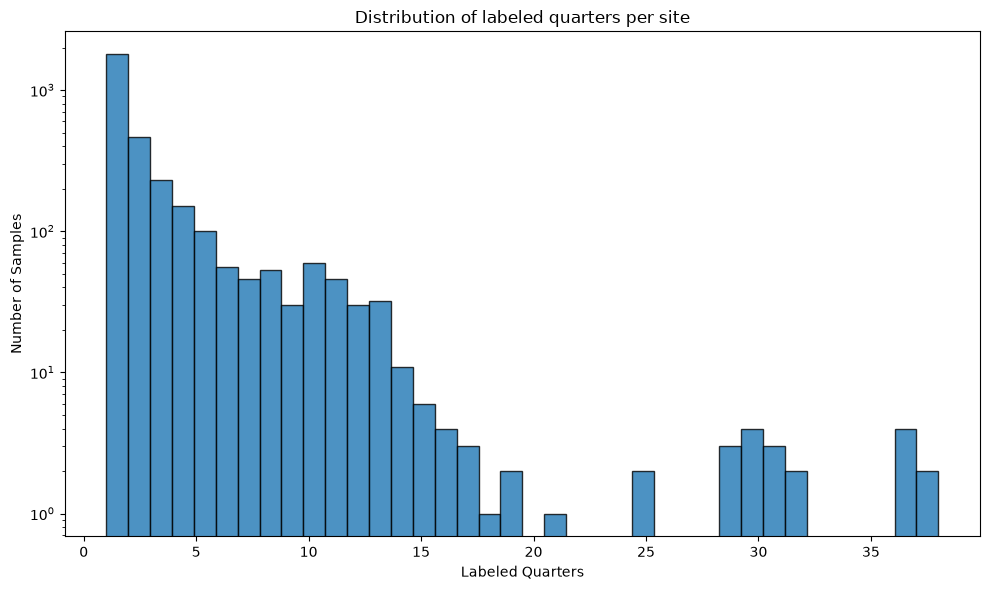

In [19]:
from matplotlib import pyplot as plt
ax = split_sites["n_label_quarters"].plot(
    kind="hist",
    bins=38,                # 38 quarters max (in all pacific dataset)
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

plt.yscale("log")  
ax.set_title("Distribution of labeled quarters per site")
ax.set_xlabel("Labeled Quarters")
ax.set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()


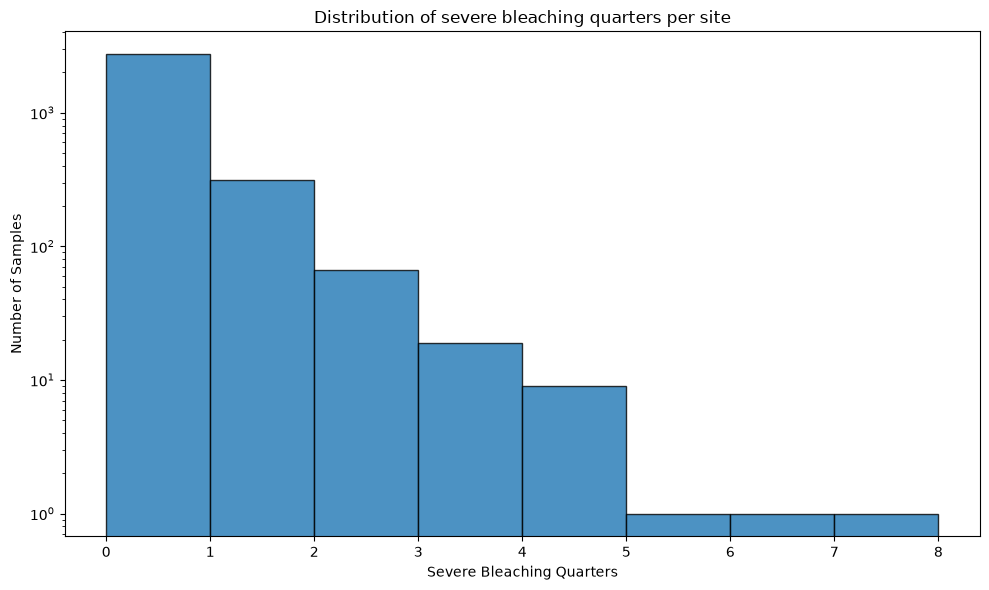

In [20]:
ax = split_sites["n_severe_bleaching"].plot(
    kind="hist",
    bins=8,                # 8 quarters max (in all pacific dataset)
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

plt.yscale("log")  
ax.set_title("Distribution of severe bleaching quarters per site")
ax.set_xlabel("Severe Bleaching Quarters")
ax.set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()


In [21]:
# bins for balancing

# categorizes number of quarters into 3 groups, with low being the biggest group
# chosen from plot above: low:0-2, medium:3-7, high:8+
split_sites["label_coverage_bin"] = pd.cut(
    split_sites["n_label_quarters"],
    bins=[-1, 2, 7, float("inf")],
    labels=["low", "medium", "high"],
)
# categorizes number of severe bleached quarters into 3 groups, with none being the biggest group
# none:0, medium:1, high: 2+
split_sites["severity_bin"] = pd.cut(
    split_sites["n_severe_bleaching"],
    bins=[-1, 0, 1, float("inf")],
    labels=["none", "medium", "high"],
)

split_sites[["site_id", "n_label_quarters", "label_coverage_bin", "n_severe_bleaching", "severity_bin"]].head(10)

,site_id,n_label_quarters,label_coverage_bin,n_severe_bleaching,severity_bin
0,001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,2,low,0,none
1,002531e9-3466-495d-b219-46912814a50a,1,low,0,none
2,00460110-a3fa-4b2c-9ed2-e071e09787b5,1,low,0,none
3,00551c69-1dd7-4742-8d2f-091ab1848e45,5,medium,1,medium
4,0069dce1-2fc9-46c7-9bce-10d8460bada7,1,low,0,none
5,0098fca8-d6c6-4859-ba06-74d5207a44ca,5,medium,0,none
6,009b5024-f412-4606-b016-497c0eb48ae2,2,low,0,none
7,009eb115-e7fe-4675-8bcf-f1803152d35b,5,medium,0,none
8,00af1f73-5481-46c8-aae1-5f6181217cd6,1,low,0,none
9,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,2,low,0,none


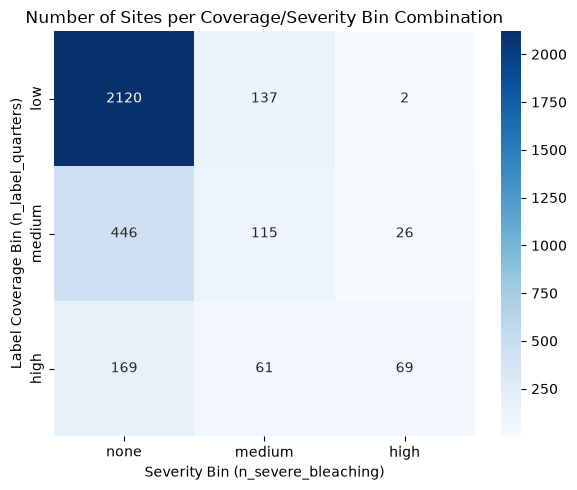

In [22]:
import seaborn as sns


bin_counts = pd.crosstab(split_sites["label_coverage_bin"], split_sites["severity_bin"])

plt.figure(figsize=(6, 5))
sns.heatmap(bin_counts, annot=True, fmt="d", cmap="Blues")
plt.title("Number of Sites per Coverage/Severity Bin Combination")
plt.xlabel("Severity Bin (n_severe_bleaching)")
plt.ylabel("Label Coverage Bin (n_label_quarters)")
plt.tight_layout()
plt.show()

In [23]:
label_coverage_counts = split_sites["label_coverage_bin"].value_counts(sort=False)
print(label_coverage_counts)
print("\nNormalized sites per label coverage bin:")
print(label_coverage_counts / label_coverage_counts.sum())


print(split_sites["severity_bin"].value_counts(sort=False))
print("\nNormalized sites per severity bin:")
severity_counts = split_sites["severity_bin"].value_counts(sort=False)
print(severity_counts / severity_counts.sum())


label_coverage_bin
low       2259
medium     587
high       299
Name: count, dtype: int64

Normalized sites per label coverage bin:
label_coverage_bin
low       0.718283
medium    0.186645
high      0.095072
Name: count, dtype: float64
severity_bin
none      2735
medium     313
high        97
Name: count, dtype: int64

Normalized sites per severity bin:
severity_bin
none      0.869634
medium    0.099523
high      0.030843
Name: count, dtype: float64


In [24]:
# group nearby sites into spatial blocks so they always end up in the same split
split_sites["spatial_block"] = (
    (split_sites["lat"] // SPATIAL_BLOCK_DEG).astype(int).astype(str)
    + "_"
    + (split_sites["lon"] // SPATIAL_BLOCK_DEG).astype(int).astype(str)
)
print(f"Sites: {len(split_sites)}, spatial blocks: {split_sites['spatial_block'].nunique()}")
split_sites[["site_id", "lat", "lon", "spatial_block"]].head(10)

Sites: 3145, spatial blocks: 239


,site_id,lat,lon,spatial_block
0,001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,-12.893750,45.212417,-13_45
1,002531e9-3466-495d-b219-46912814a50a,10.785889,124.030750,10_124
2,00460110-a3fa-4b2c-9ed2-e071e09787b5,4.152306,118.257528,4_118
3,00551c69-1dd7-4742-8d2f-091ab1848e45,10.116667,99.844444,10_99
4,0069dce1-2fc9-46c7-9bce-10d8460bada7,-26.677194,153.120028,-27_153
5,0098fca8-d6c6-4859-ba06-74d5207a44ca,10.121028,99.834861,10_99
6,009b5024-f412-4606-b016-497c0eb48ae2,-8.340278,116.028611,-9_116
7,009eb115-e7fe-4675-8bcf-f1803152d35b,5.777056,103.041750,5_103
8,00af1f73-5481-46c8-aae1-5f6181217cd6,-3.881667,122.820972,-4_122
9,00b56bab-1879-4d7d-bbc7-f5ae3ce3d541,22.829722,121.188889,22_121


In [25]:
# Count the number of sites assigned to each spatial block
sites_per_block = (
    split_sites["spatial_block"]
    .value_counts()
    .sort_index()
)

print(f"Number of different spatial blocks: {sites_per_block.size}")
print("\nNumber of sites per spatial block:")
print(sites_per_block.rename("n_sites"))


Number of different spatial blocks: 239

Number of sites per spatial block:
spatial_block
-10_119     1
-10_147     2
-11_105     2
-11_166    32
-12_169     1
           ..
9_122       4
9_123      34
9_97        6
9_98       15
9_99        1
Name: n_sites, Length: 239, dtype: int64


In [26]:
# assign whole spatial blocks to the split currently furthest below target (70/15/15), balancing overall site count AND the label_coverage_bin / severity_bin distributions 

rng = np.random.default_rng(SPLIT_RANDOM_SEED)

# randomize spatial blocks
block_groups = split_sites.groupby("spatial_block")
block_order = list(block_groups.groups.keys())
rng.shuffle(block_order) 

# Extract categories for bins
coverage_categories = split_sites["label_coverage_bin"].cat.categories
severity_categories = split_sites["severity_bin"].cat.categories

# Calculate target site counts for each split (train/val/test) based on SPLIT_TARGET_FRACTIONS
target_site_counts = {name: frac * len(split_sites) for name, frac in SPLIT_TARGET_FRACTIONS.items()}

# Calculate target counts per label_coverage_bin category for each split
target_coverage_counts = {
    name: {cat: frac * (split_sites["label_coverage_bin"] == cat).sum() for cat in coverage_categories}
    for name, frac in SPLIT_TARGET_FRACTIONS.items()
}

# Calculate target counts per severity_bin category for each split
target_severity_counts = {
    name: {cat: frac * (split_sites["severity_bin"] == cat).sum() for cat in severity_categories}
    for name, frac in SPLIT_TARGET_FRACTIONS.items()
}

# Initialize counts
current_site_counts = {name: 0 for name in SPLIT_TARGET_FRACTIONS}
current_coverage_counts = {name: {cat: 0 for cat in coverage_categories} for name in SPLIT_TARGET_FRACTIONS}
current_severity_counts = {name: {cat: 0 for cat in severity_categories} for name in SPLIT_TARGET_FRACTIONS}
block_to_split = {}  # Dictionary to store which split each spatial block is assigned to

# Iterate 
for block_name in block_order:
    block = block_groups.get_group(block_name)  
    block_coverage_counts = block["label_coverage_bin"].value_counts()  
    block_severity_counts = block["severity_bin"].value_counts()  

    # Calculate a score for each split to determine which one needs this block most (Deficits are expressed as a fraction of each category's own target (because large categories otherwise dominate sum)
    scores = {}
    for name in SPLIT_TARGET_FRACTIONS:
        site_deficit = (target_site_counts[name] - current_site_counts[name]) / max(target_site_counts[name], 1e-9)

        coverage_deficit = sum(
            (target_coverage_counts[name][cat] - current_coverage_counts[name][cat])
            / max(target_coverage_counts[name][cat], 1e-9)
            for cat in coverage_categories
        )

        severity_deficit = sum(
            (target_severity_counts[name][cat] - current_severity_counts[name][cat])
            / max(target_severity_counts[name][cat], 1e-9)
            for cat in severity_categories
        )

        # Total score: combines all three RELATIVE deficits to balance site count AND bin distributions
        scores[name] = site_deficit + coverage_deficit + severity_deficit

    # Assign the entire block to the split with the highest deficit 
    chosen_split = max(scores, key=scores.get)
    block_to_split[block_name] = chosen_split
    
    # Update current counts for the chosen split
    current_site_counts[chosen_split] += len(block)  
    for cat, count in block_coverage_counts.items():
        current_coverage_counts[chosen_split][cat] += count  
    for cat, count in block_severity_counts.items():
        current_severity_counts[chosen_split][cat] += count  

# Map each site to its assigned split based on its spatial_block
split_sites["split"] = split_sites["spatial_block"].map(block_to_split)

split_sites["split"].value_counts()

split
train    2215
test      480
val       450
Name: count, dtype: int64

In [27]:
splits_out = split_sites.copy()
splits_out["sid"] = "SID_" + splits_out["site_id"].astype(str)  # matches labels.parquet index
splits_out = splits_out[[
    "site_id", "sid", "spatial_block", "n_label_quarters", "n_severe_bleaching",
    "label_coverage_bin", "severity_bin", "split",
]]

splits_out.to_parquet(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Scripts\Labels\splits.parquet", index=False)
splits_out.head()

,site_id,sid,spatial_block,n_label_quarters,n_severe_bleaching,label_coverage_bin,severity_bin,split
0,001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,SID_001b1dc6-c2ad-4ec8-86a3-d3a8459bf355,-13_45,2,0,low,none,train
1,002531e9-3466-495d-b219-46912814a50a,SID_002531e9-3466-495d-b219-46912814a50a,10_124,1,0,low,none,train
2,00460110-a3fa-4b2c-9ed2-e071e09787b5,SID_00460110-a3fa-4b2c-9ed2-e071e09787b5,4_118,1,0,low,none,train
3,00551c69-1dd7-4742-8d2f-091ab1848e45,SID_00551c69-1dd7-4742-8d2f-091ab1848e45,10_99,5,1,medium,medium,train
4,0069dce1-2fc9-46c7-9bce-10d8460bada7,SID_0069dce1-2fc9-46c7-9bce-10d8460bada7,-27_153,1,0,low,none,test


In [28]:
print(splits_out["split"].value_counts(normalize=True))
print(splits_out.groupby("split")[["n_label_quarters", "n_severe_bleaching"]].sum())
print(pd.crosstab(splits_out["split"], splits_out["label_coverage_bin"], normalize="index"))
print(pd.crosstab(splits_out["split"], splits_out["severity_bin"], normalize="index"))

split
train    0.704293
test     0.152623
val      0.143084
Name: proportion, dtype: float64
       n_label_quarters  n_severe_bleaching
split                                      
test               1708                  89
train              5567                 389
val                1569                  79
label_coverage_bin       low    medium      high
split                                           
test                0.672917  0.243750  0.083333
train               0.737698  0.179233  0.083070
val                 0.671111  0.162222  0.166667
severity_bin      none    medium      high
split                                     
test          0.866667  0.102083  0.031250
train         0.877201  0.088036  0.034763
val           0.835556  0.153333  0.011111


### Check!
As above the normalized counts per split for label_coverage_bin and severity_bin should be close to the overall distribution in split_sites which is

In [29]:
print(label_coverage_counts / label_coverage_counts.sum())
print(severity_counts / severity_counts.sum())

label_coverage_bin
low       0.718283
medium    0.186645
high      0.095072
Name: count, dtype: float64
severity_bin
none      0.869634
medium    0.099523
high      0.030843
Name: count, dtype: float64


# Data Vizualisation

In [64]:
total_site_ids = pop["site_id"].nunique()
site_ids_depth_10m_or_less = pop.loc[
    pop["depth (m)"] <= 10, "site_id"
].nunique()

print(f"Total unique site IDs: {total_site_ids}")
print(f"Unique site IDs with depth <= 10 m: {site_ids_depth_10m_or_less}") # ACA benthic map max = 10m depth

Total unique site IDs: 4446
Unique site IDs with depth <= 10 m: 4096


## samples per country and regions

In [65]:

country_counts = (
    pop.groupby("country")
    .size()
    .reset_index(name="n_samples")
    .sort_values("n_samples", ascending=False)
)

country_region_counts = (
    pop.groupby(["country", "region"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

country_counts = country_counts.merge(country_region_counts, on="country", how="left")


country_counts_df = pd.DataFrame(country_counts)
country_counts_df.head(20)
# -> Indo-Pacific region has the most samples

,country,n_samples,Arabian Gulf,Atlantic,East Pacific,Hawaii,Indo-Pacific,Red Sea
0,Malaysia,3341,0,0,0,0,3341,0
1,Australia,1392,0,0,0,0,1392,0
2,Indonesia,1034,0,0,0,0,1034,0
3,Philippines,862,0,0,0,0,862,0
4,French Polynesia,812,0,0,0,0,812,0
5,Egypt,526,0,0,0,0,0,526
6,Fiji,484,0,0,0,0,484,0
7,Jamaica,446,0,446,0,0,0,0
8,China,328,0,0,0,0,328,0
9,Maldives,310,0,0,0,0,310,0


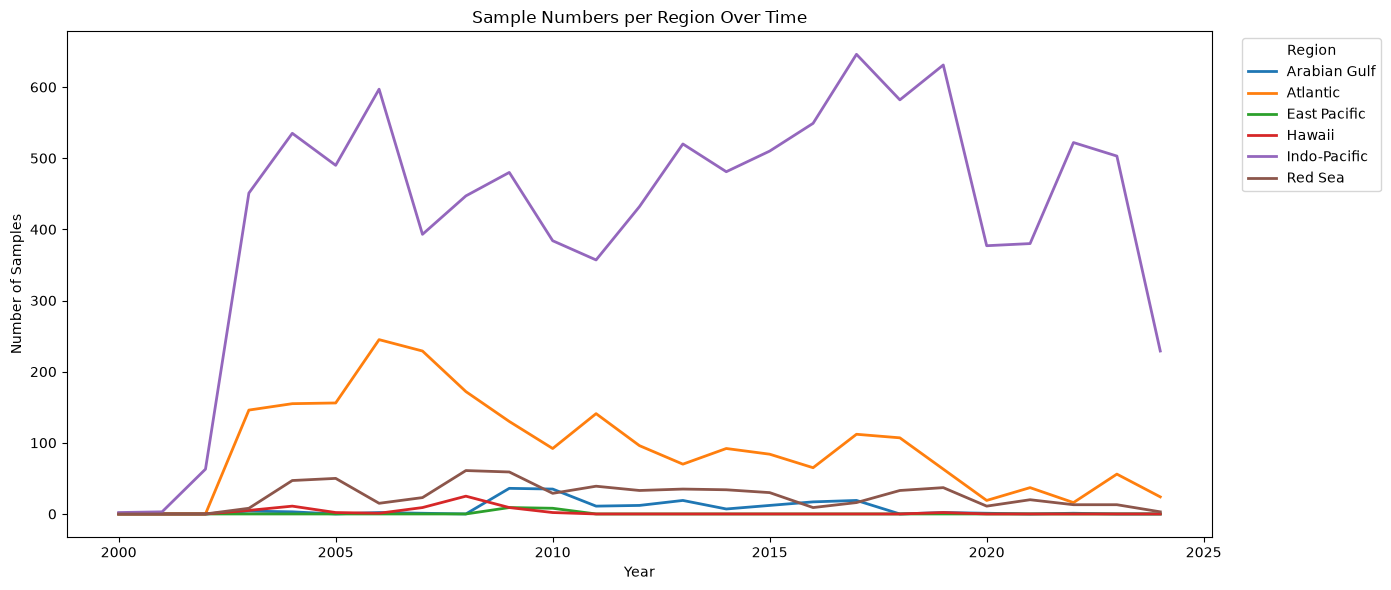

In [66]:
import matplotlib.pyplot as plt

# count samples per year and region
region_quarter_counts = (
    pop.groupby(["year", "region"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)


ax = region_quarter_counts.plot(figsize=(14, 6), linewidth=2)

ax.set_title("Sample Numbers per Region Over Time")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Samples")
ax.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

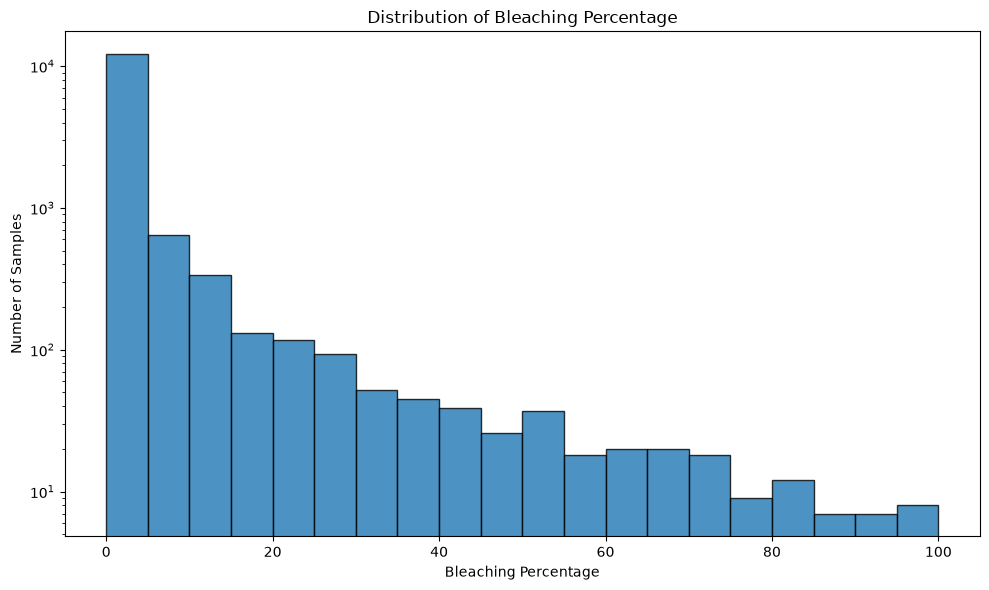

In [67]:
ax = pop["bleaching_percent"].plot(
    kind="hist",
    bins=20,                # adjust bin count for more/less detail
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

plt.yscale("log")  
ax.set_title("Distribution of Bleaching Percentage")
ax.set_xlabel("Bleaching Percentage")
ax.set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()
#->many samples with low bleaching, few with high bleaching

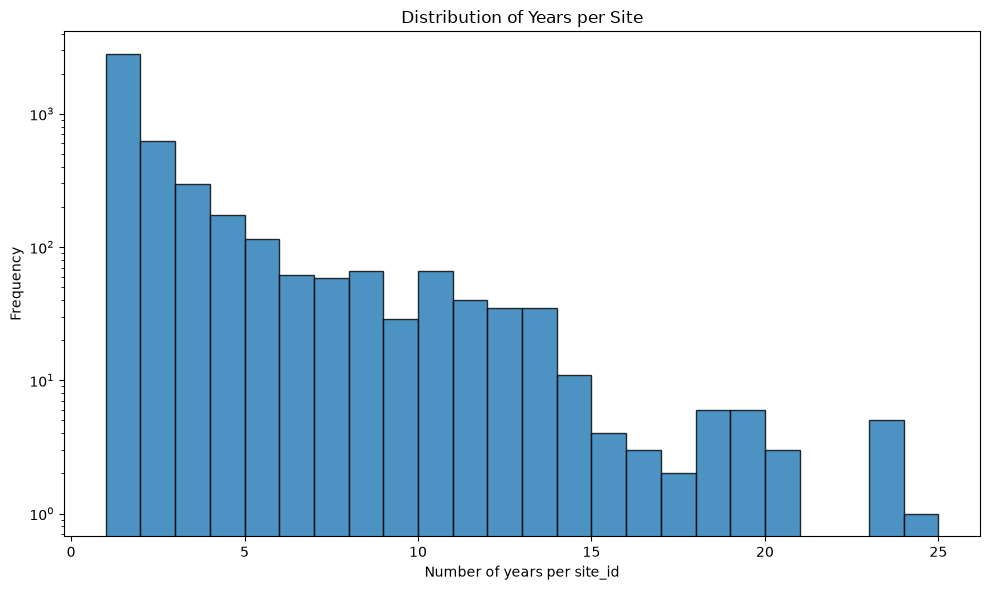

In [68]:

quarters_per_site = pop.groupby("site_id")["year"].nunique()

# Integer bins so each bar represents one "number of years"
bins = range(1, int(quarters_per_site.max()) + 2) 

ax = quarters_per_site.plot(
    kind="hist",
    bins=bins,
    figsize=(10, 6),
    edgecolor="black",
    alpha=0.8
)

ax.set_title("Distribution of Years per Site")
ax.set_xlabel("Number of years per site_id")
ax.set_ylabel("Frequency")
ax.set_yscale("log")

plt.tight_layout()
plt.show()

## Boxplot

In [69]:
import seaborn as sns
import matplotlib.pyplot as plt

In [70]:
boxplot_data = pop[pop["bleaching_percent"] > 0].copy()

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24],
 [Text(0, 0, '2000'),
  Text(1, 0, '2001'),
  Text(2, 0, '2002'),
  Text(3, 0, '2003'),
  Text(4, 0, '2004'),
  Text(5, 0, '2005'),
  Text(6, 0, '2006'),
  Text(7, 0, '2007'),
  Text(8, 0, '2008'),
  Text(9, 0, '2009'),
  Text(10, 0, '2010'),
  Text(11, 0, '2011'),
  Text(12, 0, '2012'),
  Text(13, 0, '2013'),
  Text(14, 0, '2014'),
  Text(15, 0, '2015'),
  Text(16, 0, '2016'),
  Text(17, 0, '2017'),
  Text(18, 0, '2018'),
  Text(19, 0, '2019'),
  Text(20, 0, '2020'),
  Text(21, 0, '2021'),
  Text(22, 0, '2022'),
  Text(23, 0, '2023'),
  Text(24, 0, '2024')])

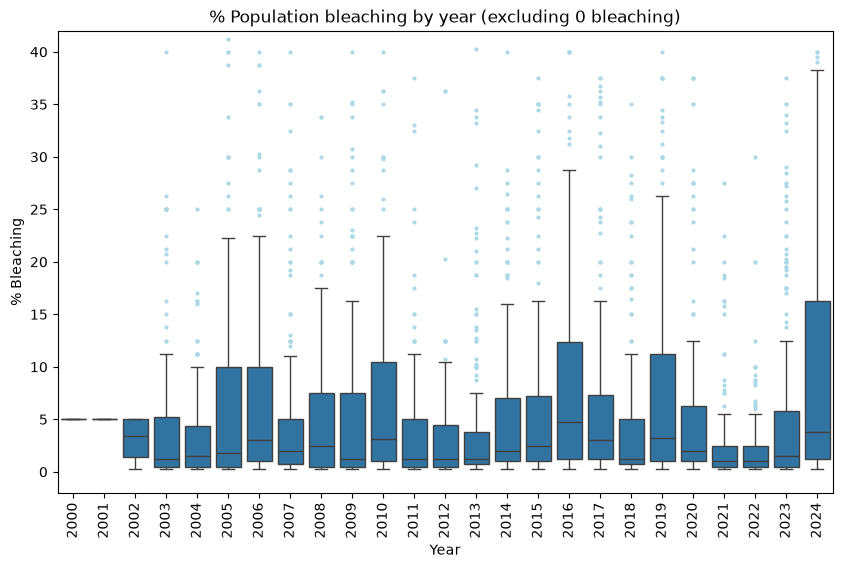

In [71]:
plt.figure(figsize=(10, 6))
flierprops = dict(marker='o', markersize=2, linestyle='none', markeredgecolor='lightblue', markerfacecolor='lightblue')
ax = sns.boxplot(x='year', y='bleaching_percent', data=boxplot_data, showfliers=True, flierprops=flierprops)
plt.title('% Population bleaching by year (excluding 0 bleaching)')
plt.xlabel('Year')
plt.ylabel('% Bleaching')
ax.set_ylim(-2, 42)
plt.xticks(rotation=90)

In [72]:
pop_indo_pacific = pop[pop["region"].isin(["Indo-Pacific"])].copy()
boxplot_data = pop_indo_pacific[pop_indo_pacific["bleaching_percent"] > 0]

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24],
 [Text(0, 0, '2000'),
  Text(1, 0, '2001'),
  Text(2, 0, '2002'),
  Text(3, 0, '2003'),
  Text(4, 0, '2004'),
  Text(5, 0, '2005'),
  Text(6, 0, '2006'),
  Text(7, 0, '2007'),
  Text(8, 0, '2008'),
  Text(9, 0, '2009'),
  Text(10, 0, '2010'),
  Text(11, 0, '2011'),
  Text(12, 0, '2012'),
  Text(13, 0, '2013'),
  Text(14, 0, '2014'),
  Text(15, 0, '2015'),
  Text(16, 0, '2016'),
  Text(17, 0, '2017'),
  Text(18, 0, '2018'),
  Text(19, 0, '2019'),
  Text(20, 0, '2020'),
  Text(21, 0, '2021'),
  Text(22, 0, '2022'),
  Text(23, 0, '2023'),
  Text(24, 0, '2024')])

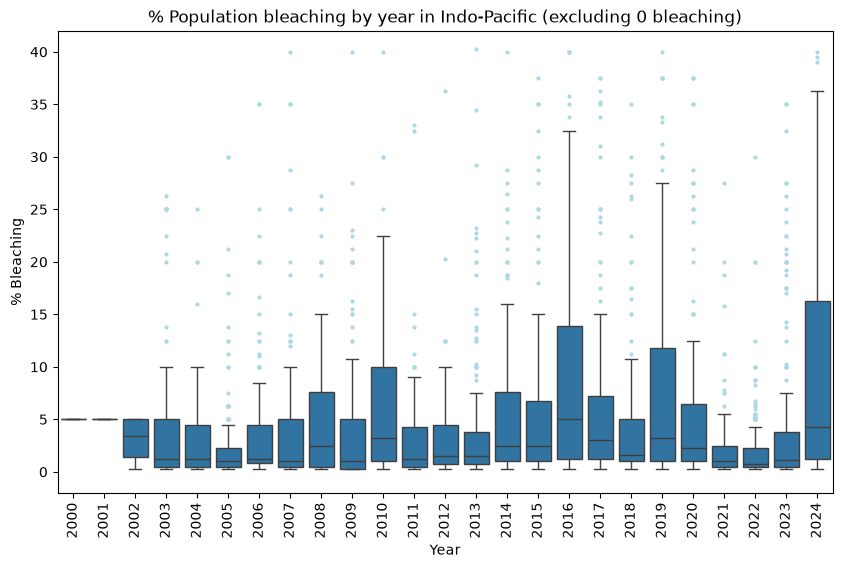

In [73]:
plt.figure(figsize=(10, 6))
flierprops = dict(marker='o', markersize=2, linestyle='none', markeredgecolor='lightblue', markerfacecolor='lightblue')
ax = sns.boxplot(x='year', y='bleaching_percent', data=boxplot_data, showfliers=True, flierprops=flierprops)
plt.title('% Population bleaching by year in Indo-Pacific (excluding 0 bleaching)')
plt.xlabel('Year')
plt.ylabel('% Bleaching')
ax.set_ylim(-2, 42)
plt.xticks(rotation=90)

## ONI 3-Month Mean Time Series (2002-2026)

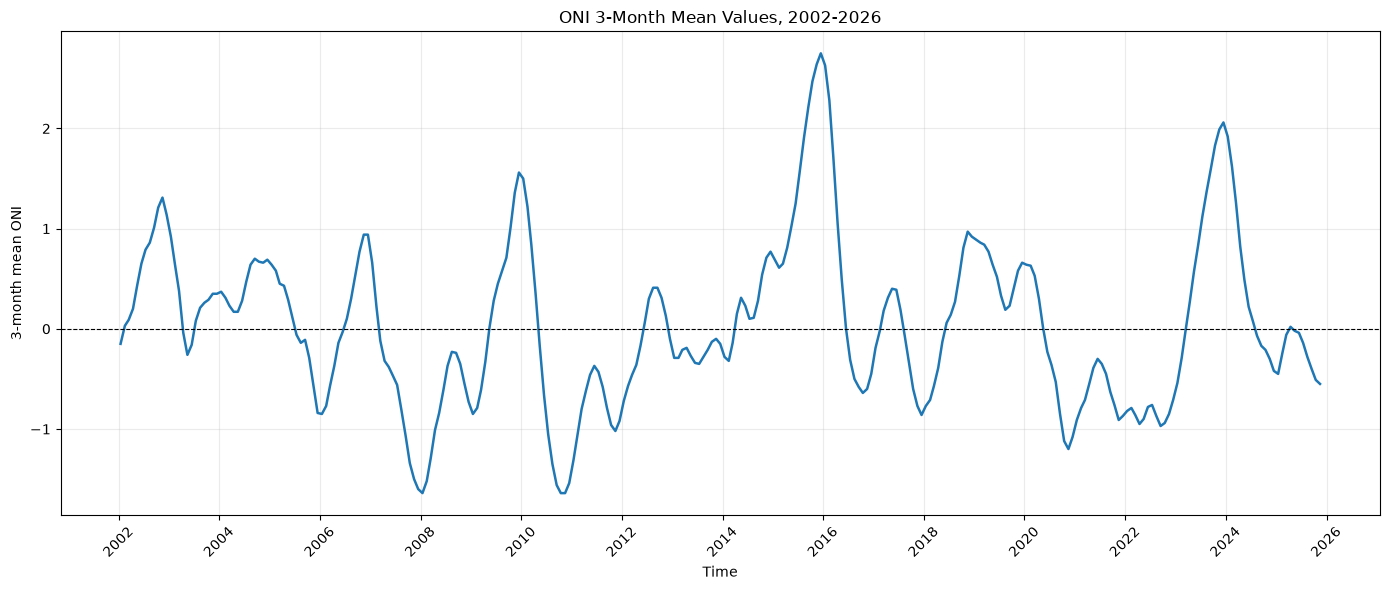

,season_start_year,season,oni_3month_mean,time
227,2001,DJF,-0.15,2002-01-15
263,2001,JFM,0.03,2002-02-15
299,2001,FMA,0.09,2002-03-15
335,2001,MAM,0.20,2002-04-15
371,2001,AMJ,0.43,2002-05-15


In [74]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

oni_path = Path(r"C:\Users\ohlle\OneDrive\Dokumente\TUM\Master\Research Practice\Docs\3-Month Mean ONI values.xlsx")
season_order = ["JJA", "JAS", "ASO", "SON", "OND", "NDJ", "DJF", "JFM", "FMA", "MAM", "AMJ", "MJJ"]

oni = pd.read_excel(oni_path)
oni.columns = [str(column).strip().upper() for column in oni.columns]

season_column = "SEASON"
missing_columns = [season for season in season_order if season not in oni.columns]
if season_column not in oni.columns or missing_columns:
    raise ValueError(f"Missing required columns: {[season_column, *missing_columns]}")

oni["season_start_year"] = pd.to_numeric(
    oni[season_column].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce",
)
oni = oni.dropna(subset=["season_start_year"]).copy()
oni["season_start_year"] = oni["season_start_year"].astype(int)

oni_long = oni.melt(
    id_vars="season_start_year",
    value_vars=season_order,
    var_name="season",
    value_name="oni_3month_mean",
)
oni_long["oni_3month_mean"] = pd.to_numeric(oni_long["oni_3month_mean"], errors="coerce")
oni_long = oni_long.dropna(subset=["oni_3month_mean"]).copy()

# Each row spans JJA of the first year through MJJ of the following year.
season_month = {
    "JJA": 7, "JAS": 8, "ASO": 9, "SON": 10,
    "OND": 11, "NDJ": 12, "DJF": 1, "JFM": 2,
    "FMA": 3, "MAM": 4, "AMJ": 5, "MJJ": 6,
}
season_year_offset = {
    "JJA": 0, "JAS": 0, "ASO": 0, "SON": 0,
    "OND": 0, "NDJ": 0, "DJF": 1, "JFM": 1,
    "FMA": 1, "MAM": 1, "AMJ": 1, "MJJ": 1,
}

oni_long["season_order"] = oni_long["season"].map({season: index for index, season in enumerate(season_order)})
oni_long["plot_year"] = oni_long["season_start_year"] + oni_long["season"].map(season_year_offset)
oni_long["plot_month"] = oni_long["season"].map(season_month)
oni_long["time"] = pd.to_datetime({
    "year": oni_long["plot_year"],
    "month": oni_long["plot_month"],
    "day": 15,
})
oni_long = oni_long[oni_long["time"].between("2002-01-01", "2026-12-31")]
oni_long = oni_long.sort_values(["time", "season_order"])

plt.figure(figsize=(14, 6))
plt.plot(
    oni_long["time"],
    oni_long["oni_3month_mean"],
    color="tab:blue",
    linewidth=1.8,
)
plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel("3-month mean ONI")
plt.title("ONI 3-Month Mean Values, 2002-2026")
plt.grid(alpha=0.25)
plt.gca().xaxis.set_major_locator(mdates.YearLocator(2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

oni_long[["season_start_year", "season", "oni_3month_mean", "time"]].head()